# 05 · Business case — combien rapporte la maintenance prédictive ?

**Question métier :** si on remplace la maintenance actuelle par notre système prédictif, combien économise-t-on par an, et ce résultat tient-il si nos hypothèses de coûts sont fausses ?

On compare **trois stratégies** sur les 100 moteurs dont on connaît toute la vie (le train) :

| Stratégie | Règle | Son défaut |
|---|---|---|
| **Réactive** | on attend que le moteur atteigne sa limite, puis on le dépose en urgence | chaque dépose est non planifiée : surcoût + avion immobilisé |
| **Préventive à intervalle fixe** | on dépose tous les moteurs au même nombre de vols T | on jette la vie des moteurs robustes, et les fragiles tombent quand même en panne avant T (notebook 01) |
| **Prédictive** | on dépose chaque moteur quand **son** scénario pessimiste descend sous une marge de sécurité | dépend de la qualité du modèle |

| # | Étape |
|---|---|
| 1 | Poser les hypothèses de coûts |
| 2 | Reprendre les prédictions honnêtes (validation par moteur) |
| 3 | Mesurer une stratégie : le coût par vol |
| 4 | Réactive et intervalle fixe (au mieux de ses possibilités) |
| 5 | Prédictive : choisir la marge de sécurité |
| 6 | Le comparatif et l'économie annuelle |
| 7 | Sensibilité : et si nos hypothèses étaient fausses ? |
| 8 | Le point mort : à partir de quand ça vaut le coup ? |
| 9 | Export Power BI et synthèse |

---
## Étape 1 · Les hypothèses de coûts

Comme au notebook 04, ce sont des **ordres de grandeur documentés, pas des chiffres Safran**. L'étape 7 teste ce qui se passe s'ils sont faux.

| Hypothèse | Valeur | Source / justification |
|---|---|---|
| Coût d'une dépose **planifiée** | 300 000 € | module de rechange du notebook 04 (250 k€) + main-d'œuvre et logistique (50 k€) |
| Surcoût d'une dépose **non planifiée** | + 40 % | une dépose non programmée coûte 30 à 50 % de plus qu'une dépose planifiée [13] : pièces en urgence, transport express, heures supplémentaires |
| Immobilisation de l'avion (AOG) en cas de dépose non planifiée | 3 jours | ordre de grandeur courant d'un AOG moteur [13] |
| Coût d'un jour d'AOG | 50 000 € | bas de la fourchette 50-150 k$ par jour [13], comme au notebook 04 |
| Rythme | 1 vol par jour, 100 moteurs | comme au notebook 04 |

Une dépose non planifiée coûte donc 300 000 × 1,4 + 3 × 50 000 = **570 000 €**, soit presque le double d'une dépose planifiée.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.append(str(Path.cwd().parent))
from src.data_loader import FIG_DIR, POWERBI_DIR, PROCESSED_DIR

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

HYPOTHESES = dict(
    depose=300_000,  # € par dépose planifiée
    surcout=0.40,  # +40 % si non planifiée
    jours_aog=3,  # jours d'immobilisation si non planifiée
    cout_aog=50_000,  # € par jour d'immobilisation
)
N_MOTEURS, VOLS_PAR_AN = 100, 365


def cout_depose(planifiee, h=HYPOTHESES):
    """Coût d'une dépose selon qu'elle a été planifiée ou subie."""
    non_planifiee = h["depose"] * (1 + h["surcout"]) + h["jours_aog"] * h["cout_aog"]
    return np.where(planifiee, h["depose"], non_planifiee)


print(
    f"Dépose planifiée : {cout_depose(True):,.0f} € · non planifiée : {cout_depose(False):,.0f} €"
)

Dépose planifiée : 300,000 € · non planifiée : 570,000 €


---
## Étape 2 · Les prédictions honnêtes

Même principe qu'aux notebooks 03 et 04 : on fait revivre les 100 moteurs du train, donc chaque prédiction doit venir d'un modèle qui **ne les a jamais vus** (validation par moteur). Le notebook 02 les a sauvegardées, on les relit. Ici, on n'a besoin que de la **borne basse** (le scénario pessimiste) : c'est elle qui déclenche la dépose dans la stratégie prédictive.

In [2]:
val = pd.read_csv(PROCESSED_DIR / "predictions_validation_FD001.csv", float_precision="round_trip")

vies = val.groupby("unit")["cycle"].max()  # vraie durée de vie de chaque moteur
moteurs = vies.index.values
print(f"{len(moteurs)} moteurs, durée de vie de {vies.min()} à {vies.max()} vols")

100 moteurs, durée de vie de 128 à 362 vols


---
## Étape 3 · Mesurer une stratégie : le coût par vol

**Le piège :** comparer le coût total des déposes ne suffit pas. La stratégie à intervalle fixe dépose les moteurs **plus tôt**, donc ils volent moins avant d'être déposés, et il faudra **plus de déposes** pour faire voler la flotte le même nombre de jours.

**La bonne mesure : le coût de maintenance par vol effectué.**

> coût par vol = (somme des coûts de dépose) / (somme des vols effectués)

**Exemple :** un moteur qui vit 200 vols.
- Prédictive : déposé (planifié) au vol 190 → 300 000 / 190 = **1 579 € par vol**.
- Intervalle fixe à 150 : déposé (planifié) au vol 150 → 300 000 / 150 = **2 000 € par vol** (50 vols de vie jetés).
- Réactive : déposé en urgence au vol 200 → 570 000 / 200 = **2 850 € par vol**.

Chaque stratégie se résume donc à un petit tableau : **pour chaque moteur, à quel vol est-il déposé, et la dépose était-elle planifiée ?**

In [3]:
def cout_par_vol(deposes, h=HYPOTHESES):
    """deposes : tableau avec une ligne par moteur, colonnes 'vols' et 'planifiee'."""
    return cout_depose(deposes["planifiee"].values, h).sum() / deposes["vols"].sum()


# ✅ Vérification sur l'exemple ci-dessus (un seul moteur de 200 vols)
assert round(cout_par_vol(pd.DataFrame({"vols": [190], "planifiee": [True]}))) == 1579
assert round(cout_par_vol(pd.DataFrame({"vols": [150], "planifiee": [True]}))) == 2000
assert round(cout_par_vol(pd.DataFrame({"vols": [200], "planifiee": [False]}))) == 2850
print("OK ✅ le coût par vol redonne l'exemple calculé à la main")

OK ✅ le coût par vol redonne l'exemple calculé à la main


---
## Étape 4 · Les stratégies de référence

**Réactive :** chaque moteur vole jusqu'à sa limite, et la dépose est toujours non planifiée.

**Intervalle fixe :** on dépose au vol T. Si le moteur atteint sa limite avant T, c'est une dépose non planifiée. Sinon, elle est planifiée au vol T, et la vie restante est jetée.

**Pour être juste avec l'intervalle fixe, on lui donne le meilleur T possible** : on essaie tous les T de 100 à 400 vols et on garde le moins cher. En vrai, un exploitant ne connaîtrait pas cet optimum à l'avance. On compare donc notre système à un adversaire **avantagé**, ce qui rend la comparaison prudente.

In [4]:
def strategie_reactive():
    return pd.DataFrame({"unit": moteurs, "vols": vies.values, "planifiee": False})


def strategie_fixe(T):
    return pd.DataFrame(
        {"unit": moteurs, "vols": np.minimum(T, vies.values), "planifiee": T < vies.values}
    )


def meilleur_intervalle(h=HYPOTHESES):
    return min(range(100, 402, 2), key=lambda T: cout_par_vol(strategie_fixe(T), h))


T_OPTIMAL = meilleur_intervalle()
courbe_fixe = pd.Series({T: cout_par_vol(strategie_fixe(T)) for T in range(100, 402, 2)})
print(f"Meilleur intervalle fixe : T = {T_OPTIMAL} vols -> {courbe_fixe[T_OPTIMAL]:,.0f} € par vol")
print(f"Réactive : {cout_par_vol(strategie_reactive()):,.0f} € par vol")

Meilleur intervalle fixe : T = 152 vols -> 2,110 € par vol
Réactive : 2,763 € par vol


---
## Étape 5 · La stratégie prédictive et sa marge de sécurité

**La règle :** chaque moteur est déposé (de façon planifiée) **au premier vol où son scénario pessimiste descend sous m vols**. Si sa limite arrive avant, c'est une dépose non planifiée.

Le lien avec le notebook 03 : l'**alerte** (scénario pessimiste ≤ 20 vols, ou prédiction ≤ 30) déclenche la **planification**, avec au moins 15 vols d'avance. La **dépose** a lieu plus tard, quand le pessimiste passe sous m. Entre les deux, la logistique commande le module (notebook 04) et réserve l'atelier.

**Le choix de m est un arbitrage :**
- m petit : on use le moteur jusqu'au bout, mais on se rapproche du risque de panne ;
- m grand : on se garde de la marge, mais on jette quelques vols de vie.

In [5]:
def strategie_predictive(m):
    """Dépose planifiée au premier vol où la borne basse <= m ; sinon dépose non planifiée en fin de vie."""
    premier_vol = val[val["rul_basse"] <= m].groupby("unit")["cycle"].min().reindex(moteurs)
    return pd.DataFrame(
        {
            "unit": moteurs,
            "vols": premier_vol.fillna(
                vies
            ).values,  # pas de déclenchement -> vole jusqu'à la limite
            "planifiee": premier_vol.notna().values,
        }
    )


marges = pd.DataFrame(
    [
        {
            "marge m": m,
            "coût par vol (€)": cout_par_vol(d := strategie_predictive(m)),
            "déposes non planifiées": int((~d["planifiee"]).sum()),
            "vols restants au minimum": int((vies.values - d["vols"].values).min()),
            "vols restants (médiane)": float(np.median(vies.values - d["vols"].values)),
        }
        for m in [0, 3, 5, 10, 15, 20]
    ]
).set_index("marge m")
marges.round(0)

,coût par vol (€),déposes non planifiées,vols restants au minimum,vols restants (médiane)
marge m,,,,
0,1854.0,30,0,0.0
3,1491.0,0,0,5.0
5,1508.0,0,1,7.0
10,1557.0,0,5,13.0
15,1608.0,0,9,19.0
20,1673.0,0,14,25.0


> **Lecture :**
> - **m = 0 est une mauvaise idée** : on attend que le pessimiste dise « 0 vol restant », c'est trop tard pour 30 moteurs.
> - **Le coût minimum est vers m = 3**, avec zéro dépose non planifiée. Mais regarde la colonne « vols restants au minimum » : **0**. Un moteur a été déposé à son tout dernier vol. Sur le papier, c'est une réussite ; dans la vraie vie, c'est une **marge nulle**. Le moindre retard d'atelier ou la moindre erreur du modèle aurait donné une panne.
> - **m = 10 coûte environ 4 % de plus que l'optimum, mais garantit au moins 5 vols de marge à chacun des 100 moteurs.**
>
> **Choix : m = 10.** C'est une décision de gestion du risque, pas d'optimisation pure. Le coût de cette prudence est chiffré, et un décideur peut la discuter. C'est exactement ce qu'on veut lui montrer.

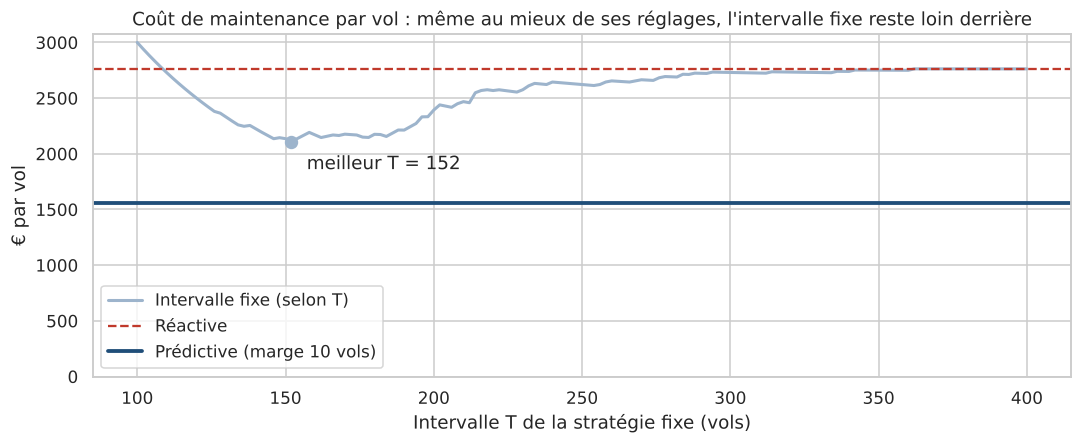

In [6]:
MARGE = 10
predictive = strategie_predictive(MARGE)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(
    courbe_fixe.index, courbe_fixe.values, color="#9db4cc", lw=2, label="Intervalle fixe (selon T)"
)
ax.scatter([T_OPTIMAL], [courbe_fixe[T_OPTIMAL]], color="#9db4cc", s=60, zorder=3)
ax.annotate(
    f"meilleur T = {T_OPTIMAL}",
    (T_OPTIMAL, courbe_fixe[T_OPTIMAL]),
    xytext=(10, -18),
    textcoords="offset points",
)
ax.axhline(cout_par_vol(strategie_reactive()), color="#c0392b", ls="--", lw=1.5, label="Réactive")
ax.axhline(
    cout_par_vol(predictive), color="#1f4e79", lw=2.5, label=f"Prédictive (marge {MARGE} vols)"
)
ax.set(
    xlabel="Intervalle T de la stratégie fixe (vols)",
    ylabel="€ par vol",
    ylim=(0, None),
    title="Coût de maintenance par vol : même au mieux de ses réglages, l'intervalle fixe reste loin derrière",
)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "19_cout_par_vol_strategies.png")
plt.show()

---
## Étape 6 · Le comparatif et l'économie annuelle

On rassemble les trois stratégies dans un seul tableau. Pour passer du coût par vol à l'économie annuelle :

> coût annuel de la flotte = coût par vol × 100 moteurs × 365 vols par an

On y ajoute le gain sur le **stock de pièces** mesuré au notebook 04 (taux de service 95 %). C'est une approximation honnête : le notebook 04 simulait des déposes en fin de vie, et le rythme de consommation de pièces de la stratégie prédictive en est très proche (elle use les moteurs jusqu'à environ 93 % de leur vie).

In [7]:
def bilan(nom, deposes):
    return {
        "stratégie": nom,
        "coût par vol (€)": cout_par_vol(deposes),
        "coût annuel flotte (M€)": cout_par_vol(deposes) * N_MOTEURS * VOLS_PAR_AN / 1e6,
        "déposes non planifiées (sur 100)": int((~deposes["planifiee"]).sum()),
        "vie utilisée (%)": 100 * deposes["vols"].sum() / vies.sum(),
    }


comparatif = pd.DataFrame(
    [
        bilan("Réactive", strategie_reactive()),
        bilan(f"Intervalle fixe (T = {T_OPTIMAL})", strategie_fixe(T_OPTIMAL)),
        bilan(f"Prédictive (marge {MARGE})", predictive),
    ]
).set_index("stratégie")
comparatif.round(1)

,coût par vol (€),coût annuel flotte (M€),déposes non planifiées (sur 100),vie utilisée (%)
stratégie,,,,
Réactive,2762.8,100.8,100,100.0
Intervalle fixe (T = 152),2109.5,77.0,7,73.3
Prédictive (marge 10),1556.8,56.8,0,93.4


In [8]:
# Gain sur le stock : on relit les simulations du notebook 04 (taux de service 95 %)
sim = pd.read_csv(PROCESSED_DIR / "simulation_stock_FD001.csv")
stock95 = sim[sim["niveau"] == 0.95].groupby("politique")["total"].mean()
gain_stock = (stock95["classique"] - stock95["pilotee"]) / 1e6

gain_maintenance = (
    comparatif["coût annuel flotte (M€)"].iloc[1] - comparatif["coût annuel flotte (M€)"].iloc[2]
)
gain_vs_reactive = (
    comparatif["coût annuel flotte (M€)"].iloc[0] - comparatif["coût annuel flotte (M€)"].iloc[2]
)

print(f"Économie de maintenance vs intervalle fixe : {gain_maintenance:5.1f} M€/an")
print(f"Économie de stock (notebook 04)             : {gain_stock:5.1f} M€/an")
print(
    f"TOTAL vs intervalle fixe                    : {gain_maintenance + gain_stock:5.1f} M€/an "
    f"({1e6 * (gain_maintenance + gain_stock) / N_MOTEURS:,.0f} € par moteur et par an)"
)
print(f"Pour mémoire, vs maintenance réactive       : {gain_vs_reactive:5.1f} M€/an de maintenance")

Économie de maintenance vs intervalle fixe :  20.2 M€/an
Économie de stock (notebook 04)             :   0.4 M€/an
TOTAL vs intervalle fixe                    :  20.5 M€/an (205,414 € par moteur et par an)
Pour mémoire, vs maintenance réactive       :  44.0 M€/an de maintenance


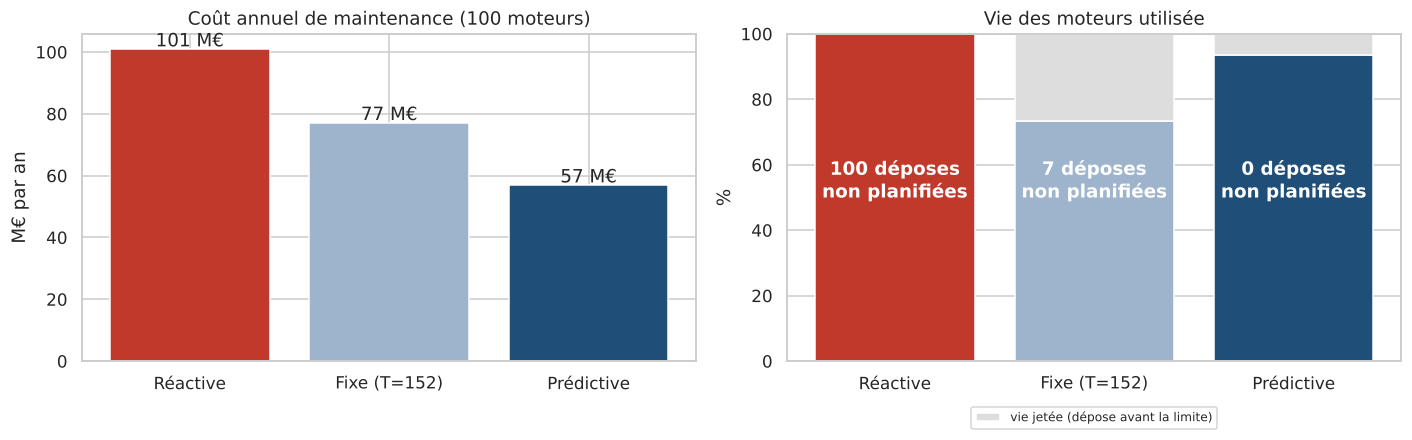

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
couleurs = ["#c0392b", "#9db4cc", "#1f4e79"]
noms_courts = ["Réactive", f"Fixe (T={T_OPTIMAL})", "Prédictive"]
axes[0].bar(noms_courts, comparatif["coût annuel flotte (M€)"], color=couleurs)
for i, v in enumerate(comparatif["coût annuel flotte (M€)"]):
    axes[0].text(i, v + 1, f"{v:.0f} M€", ha="center")
axes[0].set(title="Coût annuel de maintenance (100 moteurs)", ylabel="M€ par an")

# Droite : où partent les vols de chaque moteur ? (vie utilisée vs vie jetée, et pannes)
x = np.arange(3)
utilisee = comparatif["vie utilisée (%)"].values
axes[1].bar(x, utilisee, color=couleurs)
axes[1].bar(
    x, 100 - utilisee, bottom=utilisee, color="#dddddd", label="vie jetée (dépose avant la limite)"
)
for i, n in enumerate(comparatif["déposes non planifiées (sur 100)"]):
    axes[1].text(
        i, 50, f"{n} déposes\nnon planifiées", ha="center", color="white", fontweight="bold"
    )
axes[1].set_xticks(x, noms_courts)
axes[1].set(title="Vie des moteurs utilisée", ylabel="%", ylim=(0, 100))
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "20_comparatif_strategies.png")
plt.show()

> **Lecture :**
> - **La réactive** utilise 100 % de la vie des moteurs, mais **chaque** dépose est subie. C'est la plus chère.
> - **L'intervalle fixe**, même avec le meilleur T possible, cumule les deux défauts : il **jette environ un quart de la vie** des moteurs (les robustes sont déposés trop tôt) **et** laisse encore quelques moteurs fragiles tomber en panne avant T. C'est le dilemme du notebook 01, chiffré.
> - **La prédictive** utilise environ 93 % de la vie, **sans aucune dépose non planifiée** sur les 100 moteurs, avec au moins 5 vols de marge pour chacun.
>
> **L'essentiel du gain vient de la maintenance (environ 20 M€ par an sous nos hypothèses), le stock n'ajoute que quelques centaines de milliers d'euros.** Ce n'est pas le message qu'on attendait en commençant le projet, et c'est important de le dire : la vraie valeur, c'est d'**utiliser chaque moteur jusqu'au bout sans risquer la panne**.

---
## Étape 7 · Sensibilité : et si nos hypothèses étaient fausses ?

Nos coûts sont des ordres de grandeur. On fait varier **chaque hypothèse, une à une**, de −50 % à +50 %, et on recalcule l'économie de la prédictive face à **la meilleure alternative** (réactive ou intervalle fixe, avec son T réoptimisé à chaque fois : on reste généreux avec l'adversaire).

La marge de la prédictive reste fixée à 10 vols : c'est une règle de sécurité, on ne la réajuste pas aux coûts.

Le résultat se lit sur un **diagramme en tornade** : plus la barre est longue, plus l'économie dépend de cette hypothèse.

In [10]:
def gain_annuel(h):
    """Économie annuelle (M€) de la prédictive face à la meilleure alternative, pour des hypothèses h."""
    T = meilleur_intervalle(h)
    alternative = min(cout_par_vol(strategie_reactive(), h), cout_par_vol(strategie_fixe(T), h))
    return (alternative - cout_par_vol(predictive, h)) * N_MOTEURS * VOLS_PAR_AN / 1e6


libelles = {
    "depose": "Coût d'une dépose planifiée",
    "surcout": "Surcoût d'une dépose non planifiée",
    "jours_aog": "Jours d'immobilisation (AOG)",
    "cout_aog": "Coût d'un jour d'AOG",
}
gain_reference = gain_annuel(HYPOTHESES)
tornade = pd.DataFrame(
    [
        {
            "hypothèse": libelles[k],
            "-50 %": gain_annuel({**HYPOTHESES, k: HYPOTHESES[k] * 0.5}),
            "+50 %": gain_annuel({**HYPOTHESES, k: HYPOTHESES[k] * 1.5}),
        }
        for k in HYPOTHESES
    ]
).set_index("hypothèse")
tornade["amplitude"] = (tornade["+50 %"] - tornade["-50 %"]).abs()
tornade = tornade.sort_values("amplitude")
print(f"Économie de référence : {gain_reference:.1f} M€/an")
tornade.round(1)

Économie de référence : 20.2 M€/an


,-50 %,+50 %,amplitude
hypothèse,,,
Surcoût d'une dépose non planifiée,18.2,21.2,3.0
Jours d'immobilisation (AOG),17.2,21.4,4.2
Coût d'un jour d'AOG,17.2,21.4,4.2
Coût d'une dépose planifiée,11.3,28.2,16.8


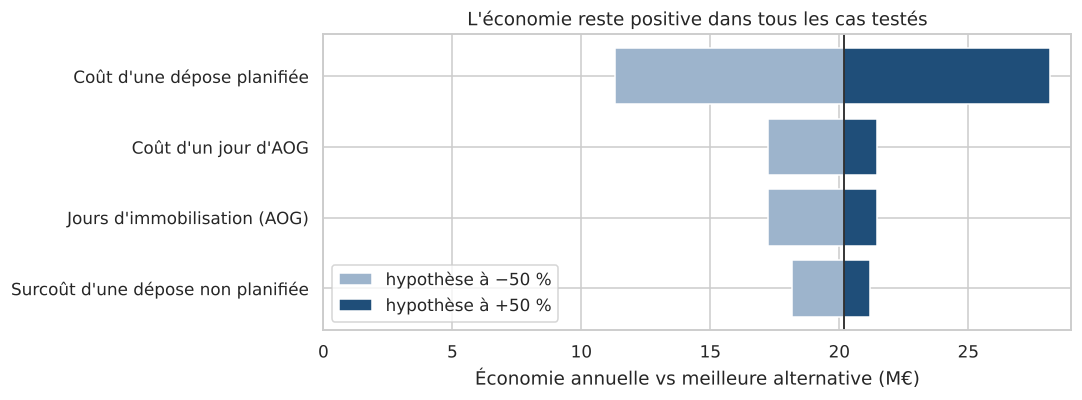

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
y = np.arange(len(tornade))
ax.barh(
    y,
    tornade["-50 %"] - gain_reference,
    left=gain_reference,
    color="#9db4cc",
    label="hypothèse à −50 %",
)
ax.barh(
    y,
    tornade["+50 %"] - gain_reference,
    left=gain_reference,
    color="#1f4e79",
    label="hypothèse à +50 %",
)
ax.axvline(gain_reference, color="black", lw=1)
ax.set_yticks(y, tornade.index)
ax.set(
    xlabel="Économie annuelle vs meilleure alternative (M€)",
    xlim=(0, None),
    title="L'économie reste positive dans tous les cas testés",
)
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(FIG_DIR / "21_tornade_sensibilite.png")
plt.show()

> **Lecture :**
> - **Dans tous les scénarios testés, l'économie reste largement positive** (au minimum une dizaine de M€ par an).
> - **L'hypothèse qui pèse le plus est le coût d'une dépose planifiée**, plus que le coût d'un AOG. C'est logique : on a vu que le gain vient surtout de la vie jetée par l'intervalle fixe, et une vie jetée coûte à proportion du prix d'une dépose.
> - **Les hypothèses sur l'AOG pèsent peu.** Tant mieux : ce sont les plus incertaines (elles viennent d'une source commerciale [13]).

---
## Étape 8 · Le point mort

Dernière question, la plus utile pour un décideur sceptique : **à partir de quelle pénalité pour une dépose non planifiée la prédictive devient-elle rentable ?**

Si une dépose subie ne coûtait **rien de plus** qu'une dépose planifiée, la meilleure stratégie serait d'attendre la panne (on utilise 100 % de la vie, sans pénalité). La prédictive, qui dépose avec 10 vols de marge, serait alors perdante (de quelques M€ par an). On fait donc monter progressivement la pénalité (surcoût + AOG), de 0 jusqu'à sa valeur de référence, et on cherche le point où les courbes se croisent.

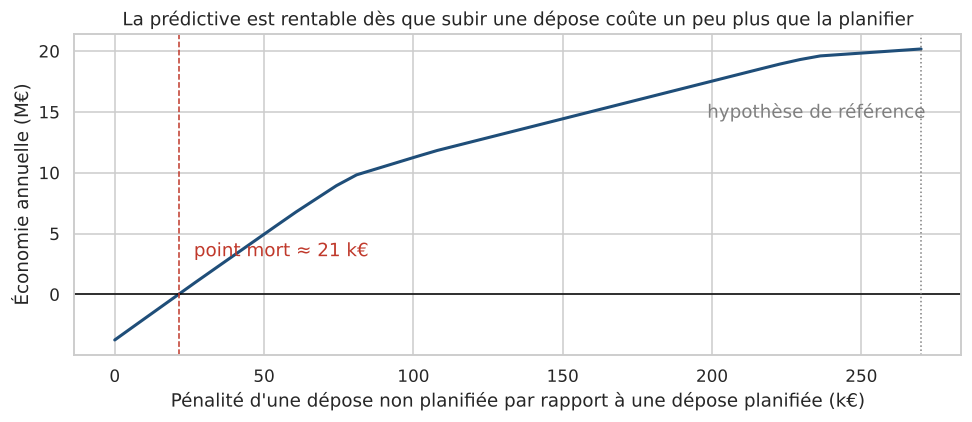

Point mort : la prédictive est rentable dès qu'une dépose non planifiée coûte 21,371 € de plus qu'une dépose planifiée, soit 7 % du coût d'une dépose.
Pour mémoire, notre hypothèse de référence est 270,000 € (90 %).


In [12]:
facteurs = np.linspace(0, 1, 41)  # 0 = aucune pénalité, 1 = hypothèses de référence
penalite = [
    HYPOTHESES["depose"] * HYPOTHESES["surcout"] * a
    + HYPOTHESES["jours_aog"] * a * HYPOTHESES["cout_aog"]
    for a in facteurs
]
gains = [
    gain_annuel(
        {
            **HYPOTHESES,
            "surcout": HYPOTHESES["surcout"] * a,
            "jours_aog": HYPOTHESES["jours_aog"] * a,
        }
    )
    for a in facteurs
]

# Le point mort : on interpole linéairement entre les deux points qui encadrent le zéro
i = int(np.argmax(np.array(gains) > 0))
point_mort = penalite[i - 1] + (0 - gains[i - 1]) * (penalite[i] - penalite[i - 1]) / (
    gains[i] - gains[i - 1]
)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.array(penalite) / 1e3, gains, color="#1f4e79", lw=2)
ax.axhline(0, color="black", lw=1)
ax.axvline(point_mort / 1e3, color="#c0392b", ls="--", lw=1)
ax.annotate(
    f"point mort ≈ {point_mort / 1e3:.0f} k€",
    (point_mort / 1e3, 0),
    xytext=(10, 25),
    textcoords="offset points",
    color="#c0392b",
)
ax.axvline(penalite[-1] / 1e3, color="grey", ls=":", lw=1)
ax.annotate(
    "hypothèse de référence",
    (penalite[-1] / 1e3, gains[-1]),
    xytext=(-140, -45),
    textcoords="offset points",
    color="grey",
)
ax.set(
    xlabel="Pénalité d'une dépose non planifiée par rapport à une dépose planifiée (k€)",
    ylabel="Économie annuelle (M€)",
    title="La prédictive est rentable dès que subir une dépose coûte un peu plus que la planifier",
)
plt.tight_layout()
plt.savefig(FIG_DIR / "22_point_mort.png")
plt.show()

print(
    f"Point mort : la prédictive est rentable dès qu'une dépose non planifiée coûte {point_mort:,.0f} € de plus "
    f"qu'une dépose planifiée, soit {100 * point_mort / HYPOTHESES['depose']:.0f} % du coût d'une dépose."
)
print(
    f"Pour mémoire, notre hypothèse de référence est {penalite[-1]:,.0f} € ({100 * penalite[-1] / HYPOTHESES['depose']:.0f} %)."
)

> **Lecture :** il suffit qu'une dépose subie coûte **moins de 10 % de plus** qu'une dépose planifiée pour que la prédictive soit rentable. Le secteur parle de +30 à +50 %, sans même compter l'immobilisation de l'avion. **La conclusion ne dépend donc pas d'une hypothèse optimiste.**

---
## Étape 9 · Export Power BI

- `fact_strategies.csv` : le comparatif des trois stratégies, pour la page d'accueil du rapport.
- `fact_sensibilite.csv` : la tornade, pour la page « robustesse ».
- `fact_marge.csv` : le coût selon la marge de sécurité, pour laisser le décideur jouer avec le curseur.

In [13]:
pbi = lambda df, nom: df.to_csv(POWERBI_DIR / nom, index=False, sep=";", decimal=",")

pbi(comparatif.reset_index().round(2), "fact_strategies.csv")
pbi(
    tornade.reset_index().round(2).assign(gain_reference=round(gain_reference, 2)),
    "fact_sensibilite.csv",
)
pbi(marges.reset_index().round(1), "fact_marge.csv")
comparatif.to_csv(PROCESSED_DIR / "business_case_FD001.csv")
print(
    "Exports écrits :", ", ".join(["fact_strategies.csv", "fact_sensibilite.csv", "fact_marge.csv"])
)

Exports écrits : fact_strategies.csv, fact_sensibilite.csv, fact_marge.csv


## Limites à connaître (et à dire)

- **Les coûts sont des hypothèses**, mais l'étape 7 montre que la conclusion résiste à ±50 % sur chacune, et l'étape 8 qu'elle tient dès une pénalité modeste.
- **Le coût du système lui-même n'est pas compté** : capteurs, collecte des données, équipe data, outil. Avec une économie de cet ordre, il faudrait qu'il coûte plusieurs millions par an pour changer la conclusion. C'est à chiffrer avec l'équipe projet.
- **On a évalué sur les 100 moteurs du train** (prédictions hors échantillon), parce que ce sont les seuls dont on connaît toute la vie. Le jeu de test, coupé avant la panne, ne permet pas de mesurer une stratégie de dépose.
- **Un seul mode de panne, des données simulées** (FD001). La prochaine étape logique serait de rejouer le projet sur FD004 (6 régimes de vol, 2 modes de panne).
- **Le gain de stock est une approximation** (notebook 04, déposes en fin de vie). Il est petit devant le gain de maintenance, donc ça ne change pas la conclusion.

## Synthèse pour le décideur

1. **Sous nos hypothèses, la maintenance prédictive économise environ 20 M€ par an sur une flotte de 100 moteurs** par rapport au meilleur intervalle fixe possible, soit environ 200 000 € par moteur et par an.
2. **D'où vient l'argent ?** Avant tout de la **vie des moteurs qu'on cesse de jeter** : l'intervalle fixe n'utilise que 73 % de la vie des moteurs, la prédictive 93 %. Le pilotage du stock (notebook 04) n'ajoute qu'une petite part.
3. **Zéro dépose non planifiée sur 100 moteurs**, avec au moins 5 vols de marge pour chacun. On a délibérément choisi une marge de sécurité qui coûte environ 2,4 M€ par an (+4 % sur le coût par vol), plutôt que de flirter avec la panne.
4. **Le résultat est robuste** : il reste positif quand on fait varier chaque hypothèse de ±50 %, et il suffit qu'une dépose subie coûte moins de 10 % de plus qu'une dépose planifiée pour que la prédictive soit gagnante.
5. **Prochaine étape :** le rapport Power BI, pour que les décideurs suivent la flotte (statuts du notebook 03), le stock (notebook 04) et ce business case.